In [53]:
from math import nan
import sklearn as sk
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [54]:
LD = pd.read_csv("OriginalDatasets/Leescatalogus_Recommender_Definitief_leesmateriaal_Jarno.csv")
LD = LD.drop_duplicates()
LD["Type materiaal"] = LD["Type materiaal"].fillna("boek")
LD

,Titel,Auteur,Korte omschrijving,Unnamed: 3,Type materiaal,Niveau,Themas_boek,materiaal_id,genre,onderwerp,...,interessecluster,uitgever,publicatiejaar,beschikbaar_formaat,cataloguscode,interne_batchcode,administratieve_prioriteit,doelgroep_extra,genre_kopie,Gemiddelde beoordeling
0,Het dagboek van Anne Frank,Anne Frank,Dagboek van een Joods meisje dat tijdens de Tw...,NaN,boek,3F,WOII;onderduik,LM-0001,fictie,WOII,...,VERHALEN,Educatief Media,2025,PDF,CAT-00001,B1,Hoog,NaN,fictie,3.4
1,Blauw Water,S. van der Vlugt,Spannende thriller waarin een vrouw wordt geco...,NaN,Boek,3F,spanning;stalking,LM-0002,fictie,spanning,...,verhalen,Leeswereld,2005,Digitaal,CAT-00002,B2,hoog,NT2,fictie,2.5
2,Boer vindt vrouw,H. van der Werf,"Toegankelijk verhaal over liefde, relaties en ...",NaN,Boek,2F,liefde;relaties,LM-0003,fictie,liefde,...,verhalen,NaN,2025,Digitaal,CAT-00003,B2,Midden,NT2,fictie,3.8
3,Cadeau voor u!,Harry Mulisch,Bundel toegankelijke verhalen over verrassende...,NaN,Boek,3F,ontmoeting;verbondenheid,LM-0004,fictie,ontmoeting,...,verhalen,Uitgeverij Noord,2018,Digitaal,CAT-00004,batch-2,Laag,NT2,fictie,3.9
4,De biecht,Mickey Roorda,Verhaal waarin verborgen geheimen en persoonli...,NaN,Boek,2F,geheimen;schuld,LM-0005,fictie,geheimen,...,verhalen,Uitgeverij Noord,NaN,online,CAT-00005,B3,Laag,MBO/NT2,fictie,3.1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
278,Zorgen om studiefinanciering: 'aanpak nodig',Lars Dekker (NOS),"criminaliteit, klimaat, media",NaN,blogpost,3F,https://www.autoriteitpersoonsgegevens.nl/arti...,LM-0279,informatief,NaN,...,verhalen,NaN,2013,Online,CAT-00279,B2,Midden,MBO,informatief,NaN
279,Wat betekent jeugdcriminaliteit voor jou?,Daan de Vries (NOS),"werk, AI, privacy, jongeren",NaN,online artikel,3F,https://www.kijkmagazine.nl/artikel/wat-beteke...,LM-0280,informatief,NaN,...,verhalen,Educatief Media,NaN,Online,CAT-00280,B2,Hoog,NaN,informatief,NaN
280,Zolang het belofte duurt,Vera Prins,Een man van veertig wordt geconfronteerd met d...,NaN,Boek - roman,2F,NaN,LM-0281,fictie,NaN,...,verhalen,NaN,2005,PDF,CAT-00281,B2,Hoog,MBO/NT2,fictie,NaN
281,Zomer zonder grens,Jelle Meijer,"Toegankelijk verhaal over onderzoek, burgersch...",NaN,Boek - thriller,2F,onderzoek;burgerschap,LM-0282,NaN,onderzoek,...,verhalen,Leeswereld,1998,Papier,CAT-00282,batch-2,Midden,NaN,NaN,NaN


In [55]:
LD["gegevensstatus"].unique()

<StringArray>
['Aangevuld (deels gesimuleerd)', 'gecontroleerd', 'In behandeling', nan]
Length: 4, dtype: str

In [56]:
LD["Type materiaal"].unique()

<StringArray>
[           'boek',            'Boek',     'tijdschrift',  'krant (papier)',
  'digitale krant', 'Boek - thriller',    'Boek - roman',  'online artikel',
     'dichtbundel',        'blogpost']
Length: 10, dtype: str

In [57]:
LD["Type materiaal"] = LD["Type materiaal"].replace(
    r"^[Bb]oek\s?-?\s?.*?$", "boek", regex=True
)
LD["Type materiaal"].unique()

<StringArray>
[          'boek',    'tijdschrift', 'krant (papier)', 'digitale krant',
 'online artikel',    'dichtbundel',       'blogpost']
Length: 7, dtype: str

<function matplotlib.pyplot.show(close=None, block=None)>

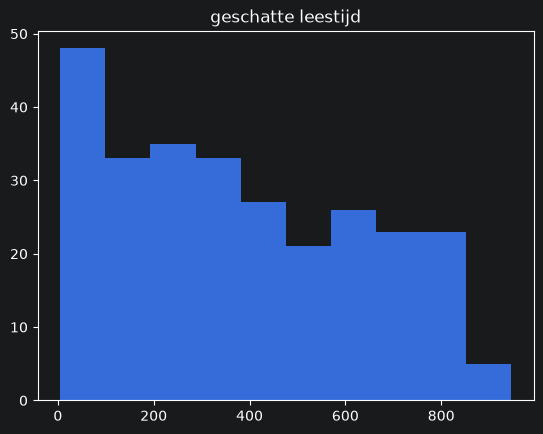

In [58]:
plt.title("geschatte leestijd")
plt.hist(LD["geschatte_leestijd_min"])
plt.show

In [65]:
LD["genre"] = LD["genre"].fillna("fiction")
LD["doelgroep"].fillna("NT2")

,Titel,Auteur,Korte omschrijving,Type materiaal,Niveau,Themas_boek,materiaal_id,genre,onderwerp,trefwoorden,...,interessecluster,uitgever,publicatiejaar,beschikbaar_formaat,cataloguscode,interne_batchcode,administratieve_prioriteit,doelgroep_extra,genre_kopie,Gemiddelde beoordeling
37,Libello voor mannen,NaN,Toegankelijk tijdschrift voor laaggeletterde l...,tijdschrift,2F,NaN,LM-0038,fictie,NaN,NaN,...,verhalen,Leeswereld,NaN,papier,CAT-00038,NaN,hoog,NaN,fictie,2.9
38,Libello voor vrouwen,NaN,Toegankelijk tijdschrift voor laaggeletterde l...,tijdschrift,2F,NaN,LM-0039,fictie,NaN,NaN,...,verhalen,Uitgeverij Noord,2013,Papier,CAT-00039,batch-2,Laag,NT2,fictie,3.5
39,De Startkrant,NaN,Eenvoudig geschreven krant met actueel nieuws ...,krant (papier),2F,NaN,LM-0040,fictie,NaN,NaN,...,verhalen,Leeswereld,2099,Papier,CAT-00040,batch-2,NaN,NaN,fictie,3.3
40,De Startweekkrant,NaN,Wekelijkse digitale krant met begrijpelijke ar...,digitale krant,2F,NaN,LM-0041,fictie,NaN,NaN,...,verhalen,Leeswereld,NaN,Digitaal,CAT-00041,NaN,Midden,NT2,fictie,3.1
156,"Tekorten zorgpersoneel nemen sneller toe, 'hoo...",NOS,"Zorg, arbeidsmarkt",online artikel,3F,https://nos.nl/artikel/2548636-tekorten-zorgpe...,LM-0157,informatief,NaN,NaN,...,verhalen,NaN,2013,PDF,CAT-00157,B3,Hoog,NaN,informatief,3.5
157,Nieuwe generatie fysiotherapeuten valt uit na ...,Sander Zurhake (NOS),"Fysiotherapie, zorg",online artikel,3F,https://nos.nl/artikel/2476626-nieuwe-generati...,LM-0158,informatief,NaN,NaN,...,verhalen,Leeswereld,2023,online,CAT-00158,batch-2,Midden,NT2,informatief,3.5


In [70]:
#Fix doelgroepen
LD["doelgroep"] = LD["doelgroep"].replace("mbo", "MBO")
LD["doelgroep"] = LD["doelgroep"].replace("mbo / nt2", "MBO/NT2")
#Dit zijn (gechecked) kranten/magazines
LD["doelgroep"]=LD["doelgroep"].fillna("NT2")
LD["doelgroep"].unique()

<StringArray>
['MBO', 'MBO/NT2', 'NT2']
Length: 3, dtype: str

In [59]:
# Geschatte leestijd invullen
imp_frequent = sk.impute.SimpleImputer(missing_values=nan, strategy="mean")
imp_frequent.fit(LD)

ValueError: Cannot use mean strategy with non-numeric data:
could not convert string to float: 'Het dagboek van Anne Frank'

In [75]:
LD[(LD["Themas_boek"].notnull())]

,Titel,Auteur,Korte omschrijving,Type materiaal,Niveau,Themas_boek,materiaal_id,genre,onderwerp,trefwoorden,...,interessecluster,uitgever,publicatiejaar,beschikbaar_formaat,cataloguscode,interne_batchcode,administratieve_prioriteit,doelgroep_extra,genre_kopie,Gemiddelde beoordeling
0,Het dagboek van Anne Frank,Anne Frank,Dagboek van een Joods meisje dat tijdens de Tw...,boek,3F,WOII;onderduik,LM-0001,fictie,WOII,WOII; onderduik,...,verhalen,Educatief Media,2025,PDF,CAT-00001,B1,Hoog,NaN,fictie,3.4
1,Blauw Water,S. van der Vlugt,Spannende thriller waarin een vrouw wordt geco...,boek,3F,spanning;stalking,LM-0002,fictie,spanning,spanning; stalking,...,verhalen,Leeswereld,2005,Digitaal,CAT-00002,B2,hoog,NT2,fictie,2.5
2,Boer vindt vrouw,H. van der Werf,"Toegankelijk verhaal over liefde, relaties en ...",boek,2F,liefde;relaties,LM-0003,fictie,liefde,liefde; relaties,...,verhalen,Nbd/Biblion,2025,Digitaal,CAT-00003,B2,Midden,NT2,fictie,3.8
3,Cadeau voor u!,Harry Mulisch,Bundel toegankelijke verhalen over verrassende...,boek,3F,ontmoeting;verbondenheid,LM-0004,fictie,ontmoeting,ontmoeting; verbondenheid,...,verhalen,Uitgeverij Noord,2018,Digitaal,CAT-00004,batch-2,Laag,NT2,fictie,3.9
4,De biecht,Mickey Roorda,Verhaal waarin verborgen geheimen en persoonli...,boek,2F,geheimen;schuld,LM-0005,fictie,geheimen,geheimen; schuld,...,verhalen,Uitgeverij Noord,2011,online,CAT-00005,B3,Laag,MBO/NT2,fictie,3.1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
274,Digitale veiligheid in Nederland: de stand van...,NOS/ANP,"discriminatie, wetgeving",online artikel,3F+,https://www.nos.nl/artikel/digitale-veiligheid...,LM-0275,informatief,NaN,NaN,...,verhalen,NaN,NaN,online,CAT-00275,NaN,Midden,MBO,informatief,NaN
278,Zorgen om studiefinanciering: 'aanpak nodig',Lars Dekker (NOS),"criminaliteit, klimaat, media",blogpost,3F,https://www.autoriteitpersoonsgegevens.nl/arti...,LM-0279,informatief,NaN,NaN,...,verhalen,NaN,2013,Online,CAT-00279,B2,Midden,MBO,informatief,NaN
279,Wat betekent jeugdcriminaliteit voor jou?,Daan de Vries (NOS),"werk, AI, privacy, jongeren",online artikel,3F,https://www.kijkmagazine.nl/artikel/wat-beteke...,LM-0280,informatief,NaN,NaN,...,verhalen,Educatief Media,NaN,Online,CAT-00280,B2,Hoog,NaN,informatief,NaN
281,Zomer zonder grens,Jelle Meijer,"Toegankelijk verhaal over onderzoek, burgersch...",boek,2F,onderzoek;burgerschap,LM-0282,fiction,onderzoek,onderzoek; burgerschap,...,verhalen,Leeswereld,1998,Papier,CAT-00282,batch-2,Midden,NaN,NaN,NaN


In [16]:
ldExtract = LD[(LD["Niveau"].isnull())]
ldExtract

,Titel,Auteur,Korte omschrijving,Type materiaal,Niveau,Themas_boek,materiaal_id,genre,onderwerp,trefwoorden,...,interessecluster,uitgever,publicatiejaar,beschikbaar_formaat,cataloguscode,interne_batchcode,administratieve_prioriteit,doelgroep_extra,genre_kopie,Gemiddelde beoordeling
37,Libello voor mannen,NaN,Toegankelijk tijdschrift voor laaggeletterde l...,tijdschrift,NaN,NaN,LM-0038,fictie,NaN,NaN,...,verhalen,Leeswereld,NaN,papier,CAT-00038,NaN,hoog,NaN,fictie,2.9
38,Libello voor vrouwen,NaN,Toegankelijk tijdschrift voor laaggeletterde l...,tijdschrift,NaN,NaN,LM-0039,fictie,NaN,NaN,...,verhalen,Uitgeverij Noord,2013,Papier,CAT-00039,batch-2,Laag,NT2,fictie,3.5
39,De Startkrant,NaN,Eenvoudig geschreven krant met actueel nieuws ...,krant (papier),NaN,NaN,LM-0040,fictie,NaN,NaN,...,verhalen,Leeswereld,2099,Papier,CAT-00040,batch-2,NaN,NaN,fictie,3.3
40,De Startweekkrant,NaN,Wekelijkse digitale krant met begrijpelijke ar...,digitale krant,NaN,NaN,LM-0041,fictie,NaN,NaN,...,verhalen,Leeswereld,NaN,Digitaal,CAT-00041,NaN,Midden,NT2,fictie,3.1
156,"Tekorten zorgpersoneel nemen sneller toe, 'hoo...",NOS,"Zorg, arbeidsmarkt",online artikel,NaN,https://nos.nl/artikel/2548636-tekorten-zorgpe...,LM-0157,informatief,NaN,NaN,...,verhalen,NaN,2013,PDF,CAT-00157,B3,Hoog,NaN,informatief,3.5
157,Nieuwe generatie fysiotherapeuten valt uit na ...,Sander Zurhake (NOS),"Fysiotherapie, zorg",online artikel,NaN,https://nos.nl/artikel/2476626-nieuwe-generati...,LM-0158,informatief,NaN,NaN,...,verhalen,Leeswereld,2023,online,CAT-00158,batch-2,Midden,NT2,informatief,3.5


In [72]:
# Fixing Theme Boeken
# Articelen bron IN Themas verwijderen.

,Titel,Auteur,Korte omschrijving,Unnamed: 3,Type materiaal,Niveau,Themas_boek,materiaal_id,genre,onderwerp,...,interessecluster,uitgever,publicatiejaar,beschikbaar_formaat,cataloguscode,interne_batchcode,administratieve_prioriteit,doelgroep_extra,genre_kopie,Gemiddelde beoordeling
0,Het dagboek van Anne Frank,Anne Frank,Dagboek van een Joods meisje dat tijdens de Tw...,NaN,boek,3F,WOII;onderduik,LM-0001,fictie,WOII,...,VERHALEN,Educatief Media,2025,PDF,CAT-00001,B1,Hoog,NaN,fictie,3.4
1,Blauw Water,S. van der Vlugt,Spannende thriller waarin een vrouw wordt geco...,NaN,boek,3F,spanning;stalking,LM-0002,fictie,spanning,...,verhalen,Leeswereld,2005,Digitaal,CAT-00002,B2,hoog,NT2,fictie,2.5
2,Boer vindt vrouw,H. van der Werf,"Toegankelijk verhaal over liefde, relaties en ...",NaN,boek,2F,liefde;relaties,LM-0003,fictie,liefde,...,verhalen,NaN,2025,Digitaal,CAT-00003,B2,Midden,NT2,fictie,3.8
3,Cadeau voor u!,Harry Mulisch,Bundel toegankelijke verhalen over verrassende...,NaN,boek,3F,ontmoeting;verbondenheid,LM-0004,fictie,ontmoeting,...,verhalen,Uitgeverij Noord,2018,Digitaal,CAT-00004,batch-2,Laag,NT2,fictie,3.9
4,De biecht,Mickey Roorda,Verhaal waarin verborgen geheimen en persoonli...,NaN,boek,2F,geheimen;schuld,LM-0005,fictie,geheimen,...,verhalen,Uitgeverij Noord,NaN,online,CAT-00005,B3,Laag,MBO/NT2,fictie,3.1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
278,Zorgen om studiefinanciering: 'aanpak nodig',Lars Dekker (NOS),"criminaliteit, klimaat, media",NaN,blogpost,3F,https://www.autoriteitpersoonsgegevens.nl/arti...,LM-0279,informatief,NaN,...,verhalen,NaN,2013,Online,CAT-00279,B2,Midden,MBO,informatief,NaN
279,Wat betekent jeugdcriminaliteit voor jou?,Daan de Vries (NOS),"werk, AI, privacy, jongeren",NaN,online artikel,3F,https://www.kijkmagazine.nl/artikel/wat-beteke...,LM-0280,informatief,NaN,...,verhalen,Educatief Media,NaN,Online,CAT-00280,B2,Hoog,NaN,informatief,NaN
280,Zolang het belofte duurt,Vera Prins,Een man van veertig wordt geconfronteerd met d...,NaN,boek,2F,NaN,LM-0281,fictie,NaN,...,verhalen,NaN,2005,PDF,CAT-00281,B2,Hoog,MBO/NT2,fictie,NaN
281,Zomer zonder grens,Jelle Meijer,"Toegankelijk verhaal over onderzoek, burgersch...",NaN,boek,2F,onderzoek;burgerschap,LM-0282,fiction,onderzoek,...,verhalen,Leeswereld,1998,Papier,CAT-00282,batch-2,Midden,NaN,NaN,NaN
